**copied from /admin-where-is-M1/w1-extract-cm229-topo.ipynb**

In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
from f2_utils import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches

import time_in_each_roi 

In [3]:
prefix = '/mnt/staging/' # or 
step_0_root = str(STEPS / "step_0/RS_3mice") + "/"
step_1_root = str(STEPS / "step_1") + "/"
mouse='cm128'

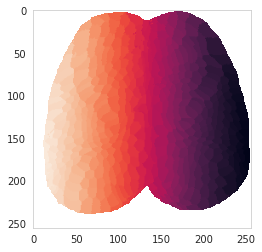

In [4]:
with h5py.File(step_0_root+'idx_sorted_500_{}.mat'.format(mouse),'r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'
plt.imshow(IDX_sorted)

In [5]:
M_raw={}
t1 = 340
with h5py.File(step_1_root+'{}/{}/{}_stim_1.mat'.format(mouse,'1','runB'),'r') as f_H: 
    for key in ['green','lime','red']:
        C = np.array(f_H['C'][key])
        S = np.array(f_H['S'][key])[t1:t1+1,:]
        CS = np.dot(S,C).transpose()

        temp = CS
        temp = temp.reshape((256,256,-1)).transpose((1,0,2))     

        # temp_norm = temp-np.mean(temp[:,:,bsl],axis=-1)[:,:,np.newaxis]
        M_raw[key] = temp


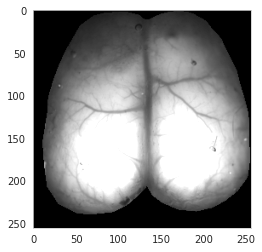

In [6]:
masked_brain = np.multiply(np.squeeze(M_raw['lime']),mask)
masked_brain=np.nan_to_num(masked_brain,0)
plt.imshow(masked_brain,cmap='gray',vmin=0,vmax=4300)

In [7]:
load_config_root = str(PREPARES / "config") + "/"
palatte_dict = load_pickle(load_config_root+'palatte_dict')
palatte_dict['mouth_M2']='#bf8fc9'
palatte_dict['RFP_M2']='#6dae96'
palatte_dict['RFP_M1']='#4b0082'
palatte_dict['RV']='lightseagreen'




In [8]:
def save_pickle(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file)

def load_pickle(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model

def load_prepare_data(X_continued, y_continued,length=40,stride_length=5,num_regions=500):
    # split training, testing set
    X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size=0.6,shuffle=True,random_state=7)
    print(X_train.shape, X_test.shape, Y_train.shape, Y_test.shape)
    dataDict ={'X_train':X_train,
          'X_test':X_test,
          'y_train':Y_train,
          'y_test':Y_test}

    return dataDict

In [9]:
# load CNN model
from prepare_CNN_model import prepare_model
from prepare_CNN_model import load_model
from prepare_CNN_model import load_prepare_data
from prepare_CNN_model import prepare_model_linear_act
from prepare_CNN_model import prepare_model_without_lstm


In [10]:
from sklearn.metrics import mean_squared_error,r2_score

palette_body=['#e97877','#85A2B2','#7ba379','#f4c784']


cm125
26 ['cm125_1_runB', 'cm125_1_runC', 'cm125_1_runD', 'cm125_1_runE', 'cm125_1_runF', 'cm125_1_runG', 'cm125_1_runI', 'cm125_1_runJ', 'cm125_2_runB', 'cm125_2_runC', 'cm125_2_runD', 'cm125_2_runE', 'cm125_2_runF', 'cm125_2_runG', 'cm125_2_runH', 'cm125_2_runI', 'cm125_2_runJ', 'cm125_3_runB', 'cm125_3_runC', 'cm125_3_runD', 'cm125_3_runE', 'cm125_3_runF', 'cm125_3_runG', 'cm125_3_runH', 'cm125_3_runI', 'cm125_3_runJ']
Model: "model_6"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_7 (InputLayer)        [(None, 40, 500)]         0         
                                                                 
 conv1d_6 (Conv1D)           (None, 40, 1024)          10241024  
                                                                 
 dense_18 (Dense)            (None, 40, 128)           131200    
                                                                 
 dense_19 (Dense)            

/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:68: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).


9/9 [==============================] - 0s 27ms/step
cm126
16 ['cm126_1_runB', 'cm126_1_runF', 'cm126_1_runG', 'cm126_1_runH', 'cm126_1_runI', 'cm126_1_runJ', 'cm126_2_runF', 'cm126_2_runG', 'cm126_2_runH', 'cm126_2_runI', 'cm126_2_runJ', 'cm126_3_runB', 'cm126_3_runC', 'cm126_3_runH', 'cm126_3_runI', 'cm126_3_runJ']
Model: "model_8"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_9 (InputLayer)        [(None, 40, 500)]         0         
                                                                 
 conv1d_8 (Conv1D)           (None, 40, 1024)          10241024  
                                                                 
 dense_24 (Dense)            (None, 40, 128)           131200    
                                                                 
 dense_25 (Dense)            (None, 40, 64)            8256      
                                                                 
 dens

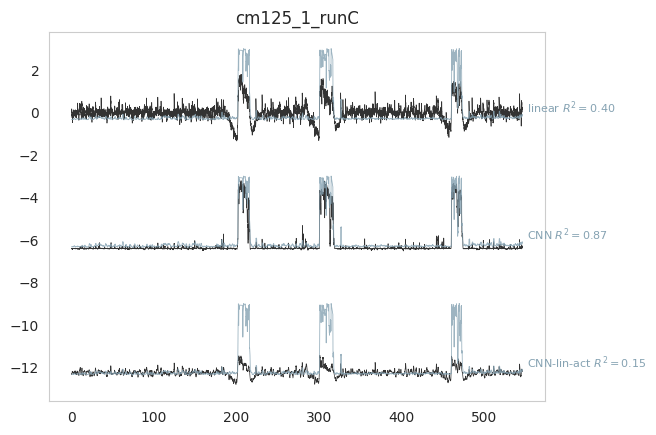

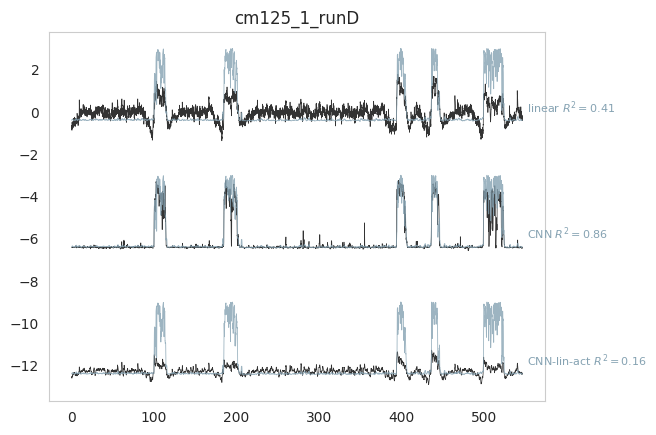

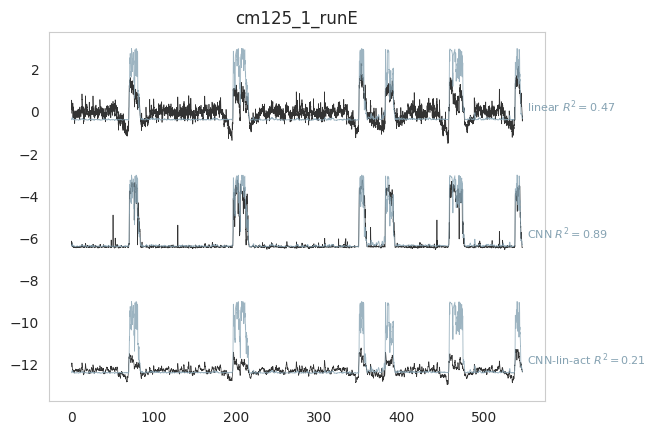

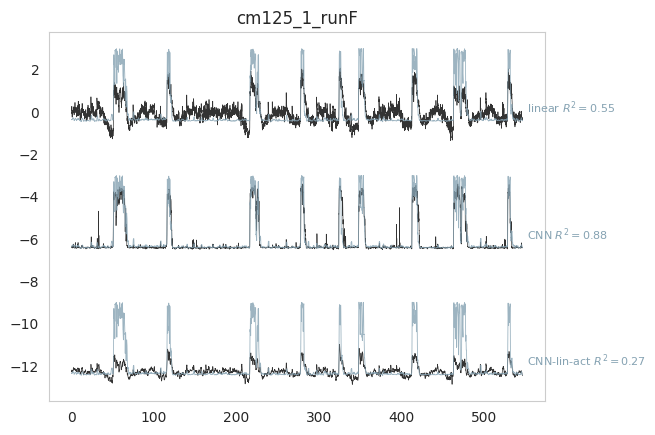

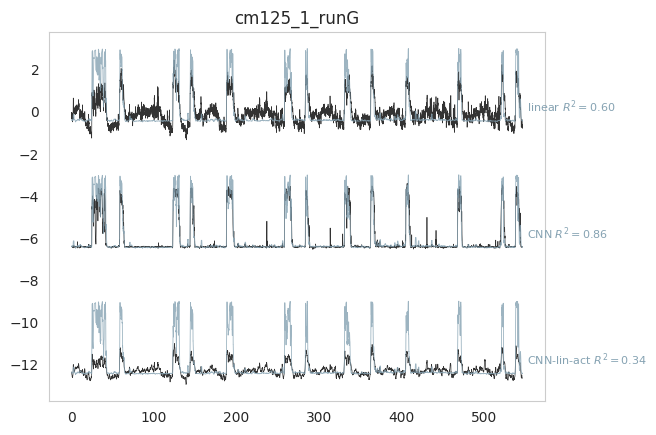

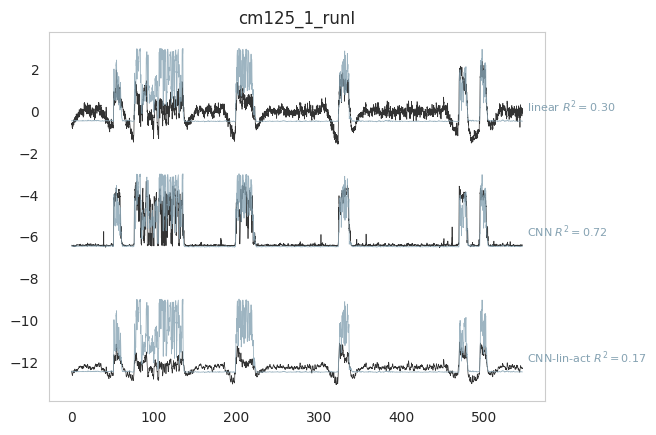

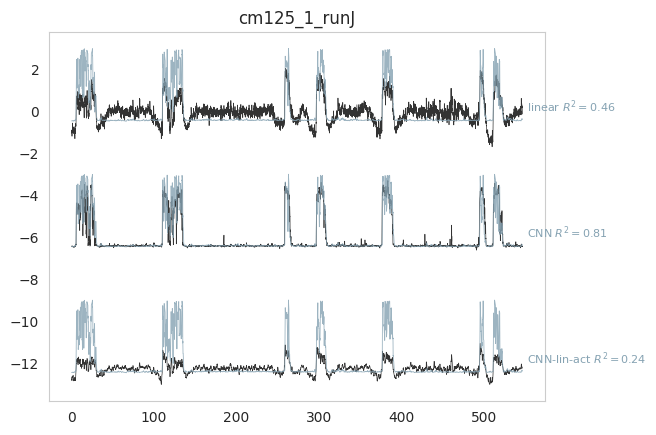

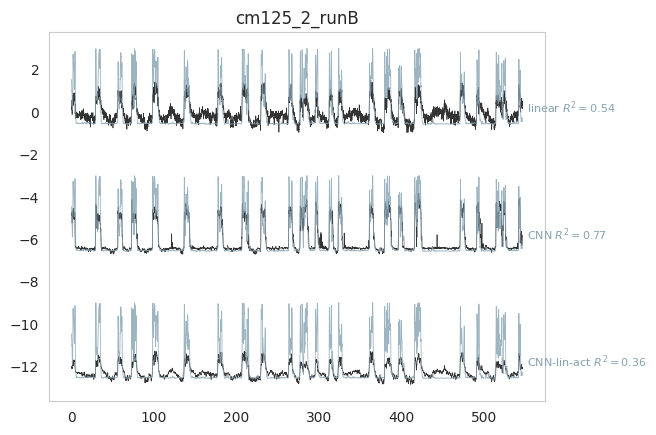

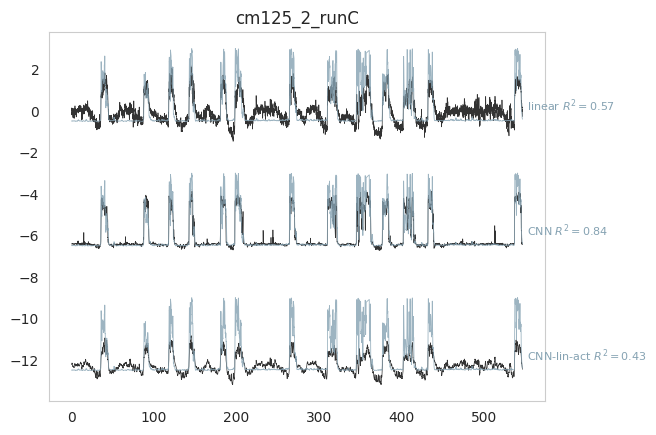

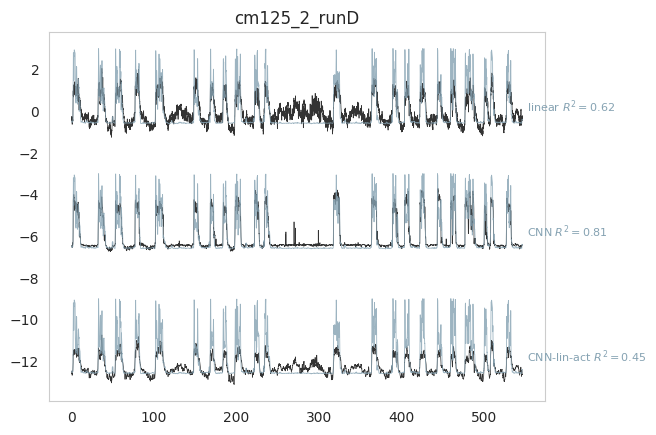

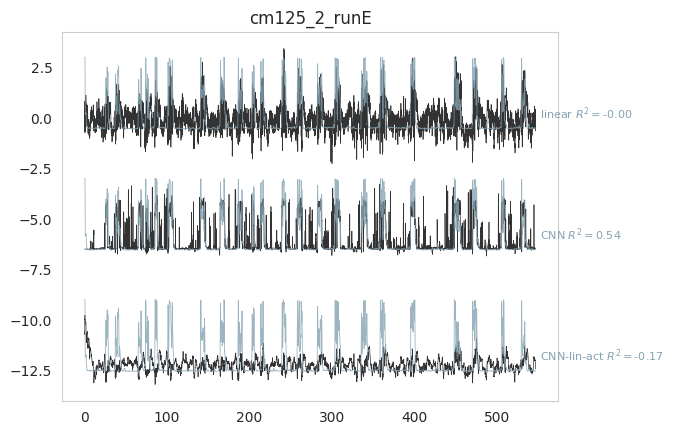

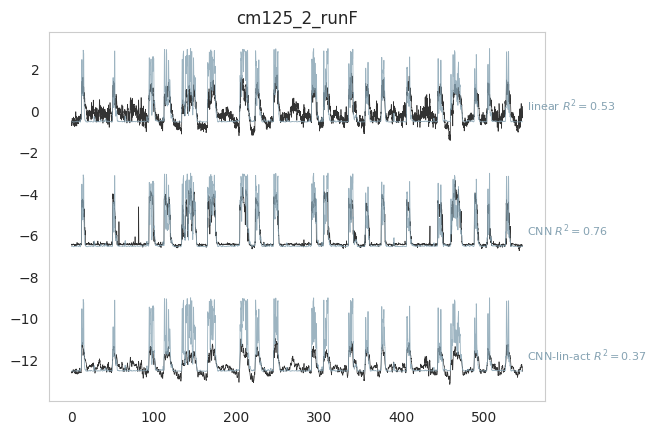

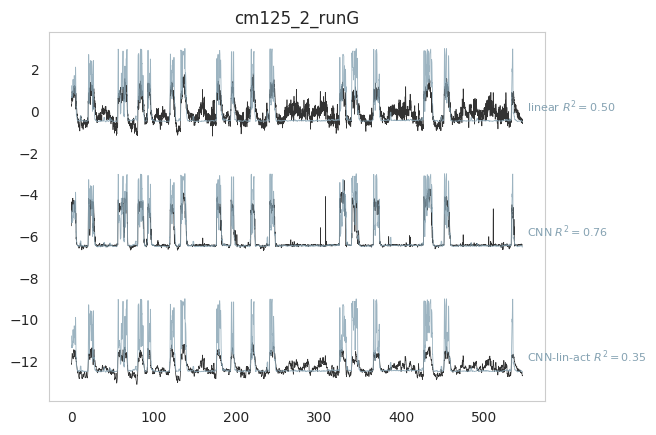

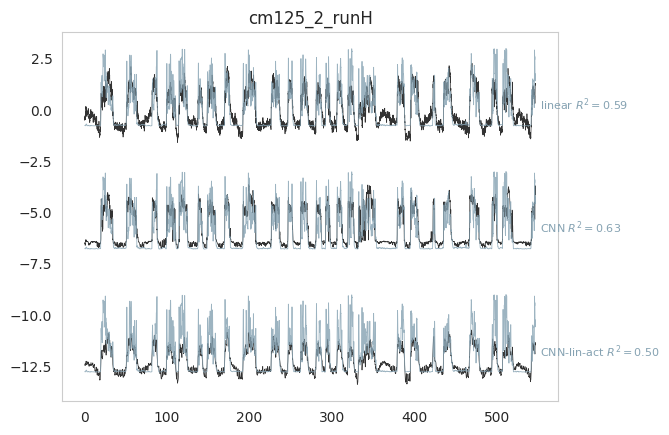

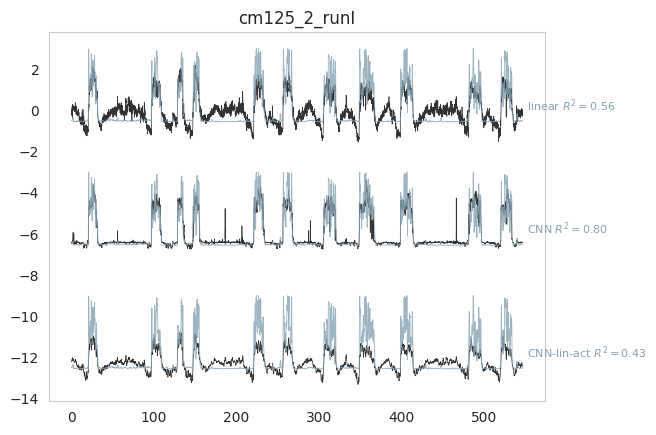

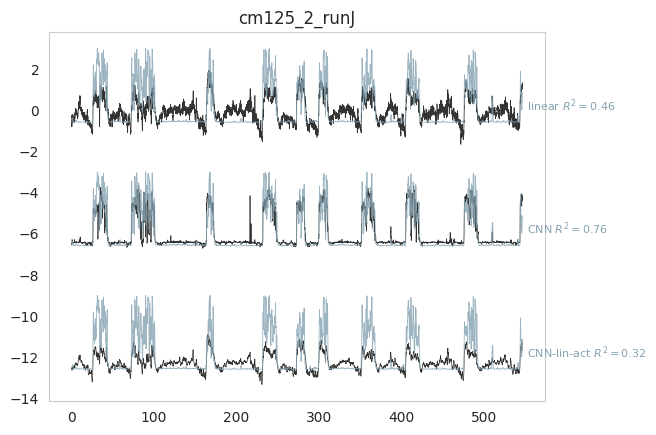

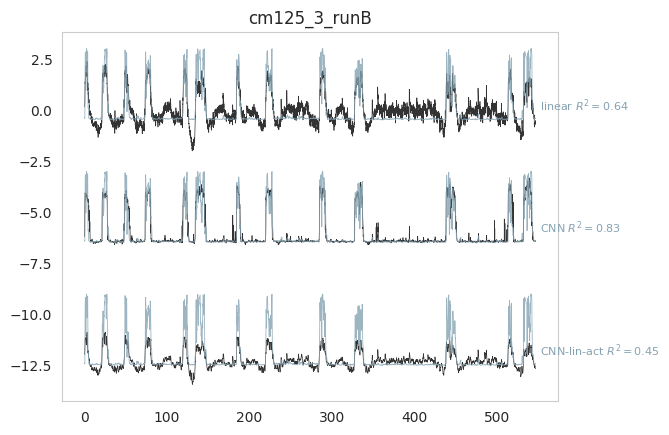

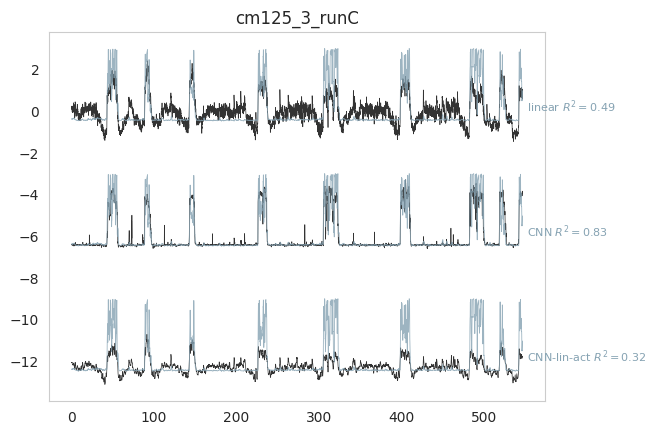

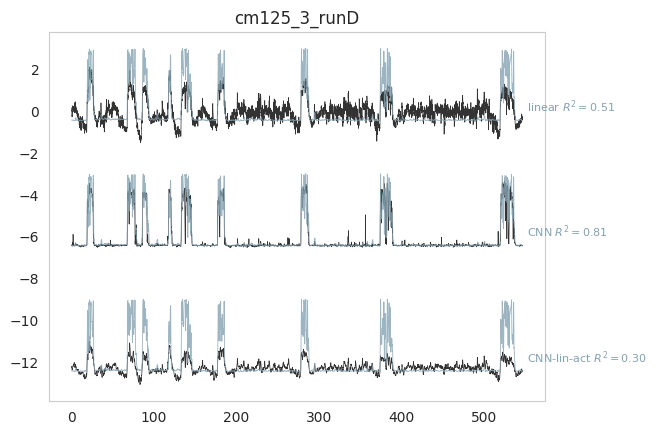

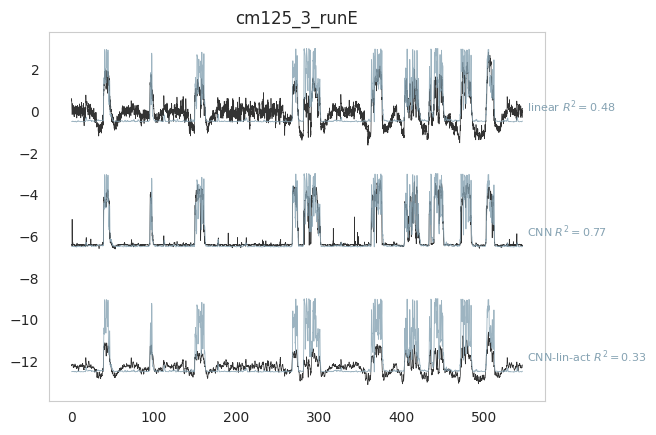

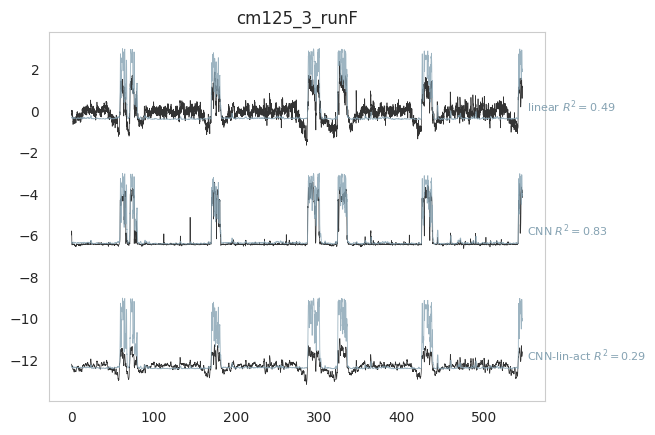

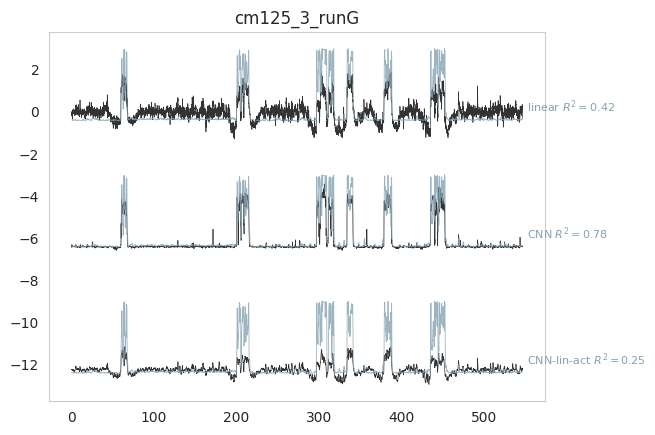

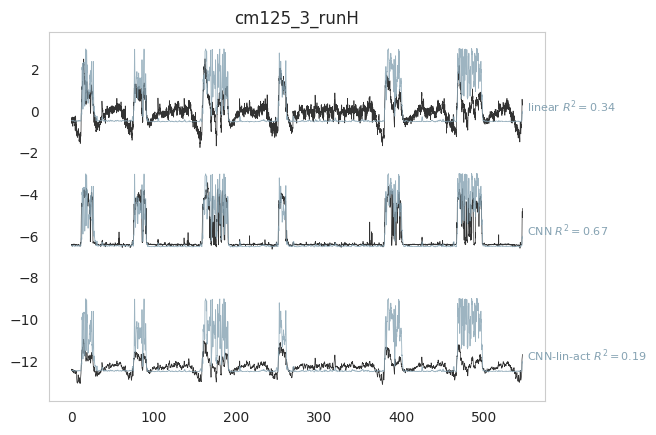

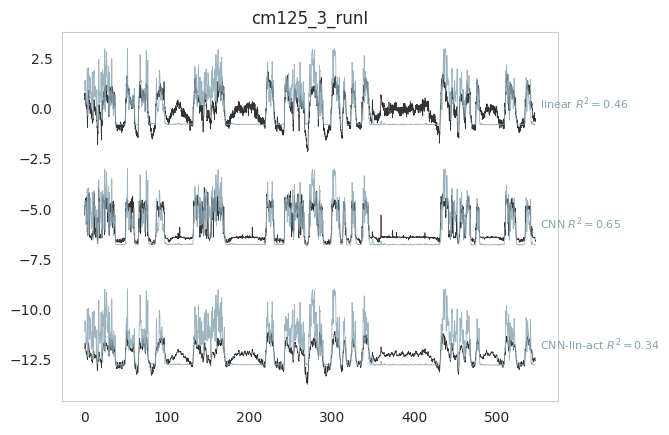

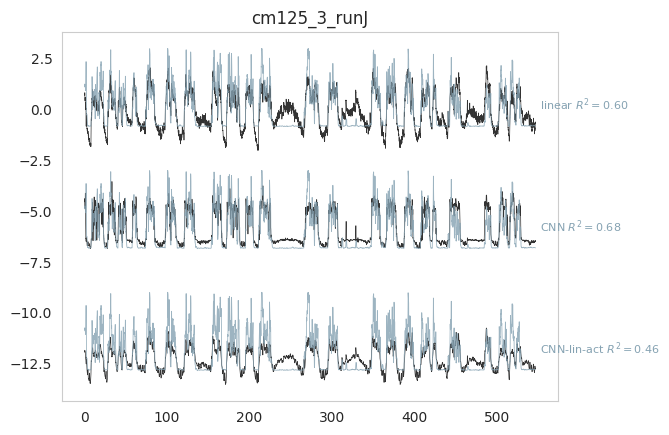

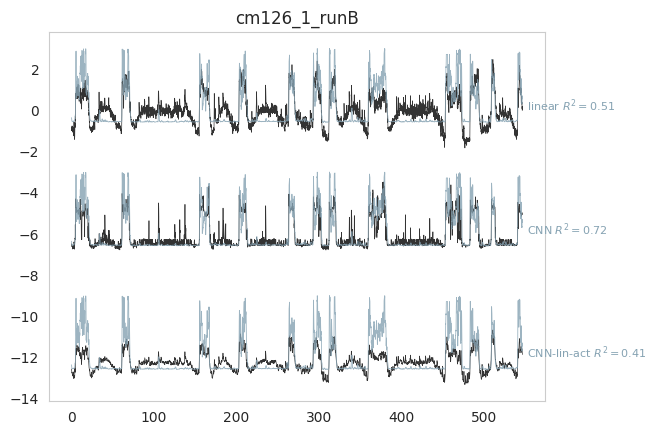

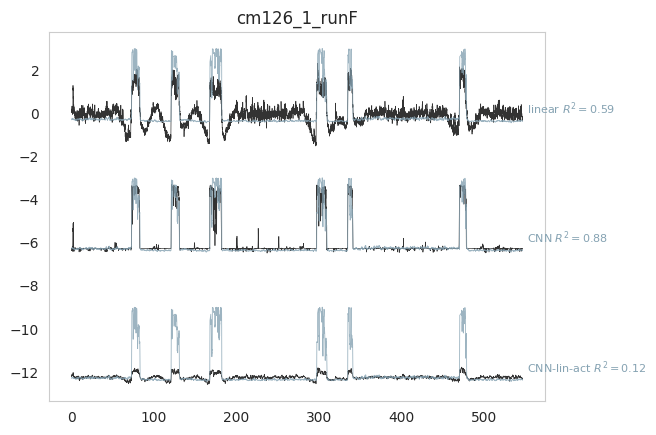

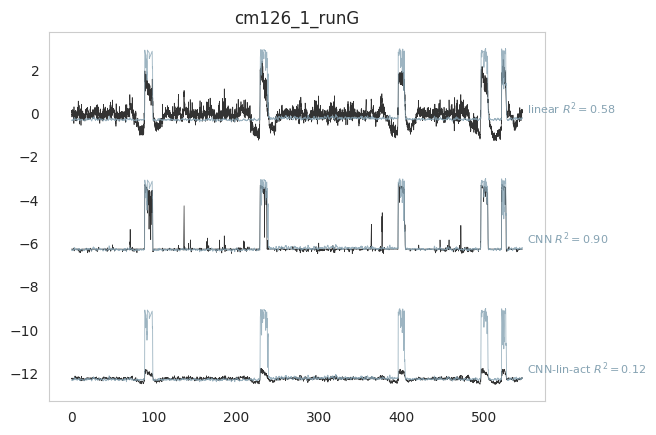

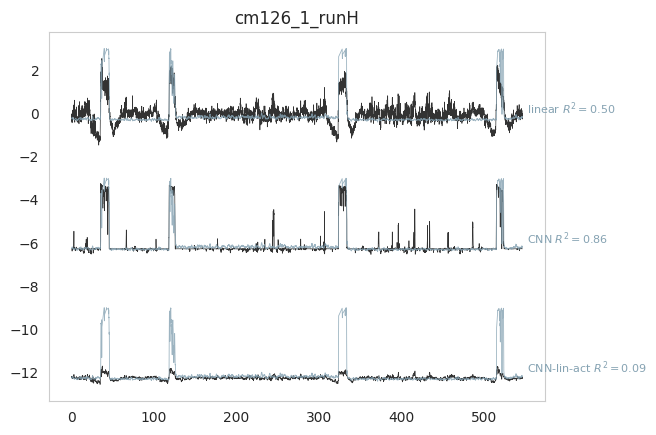

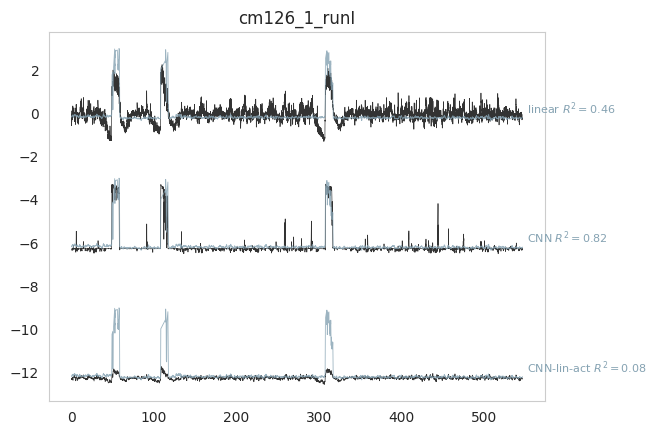

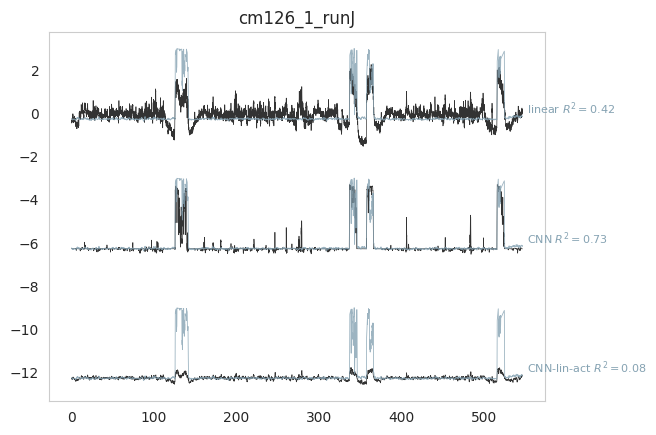

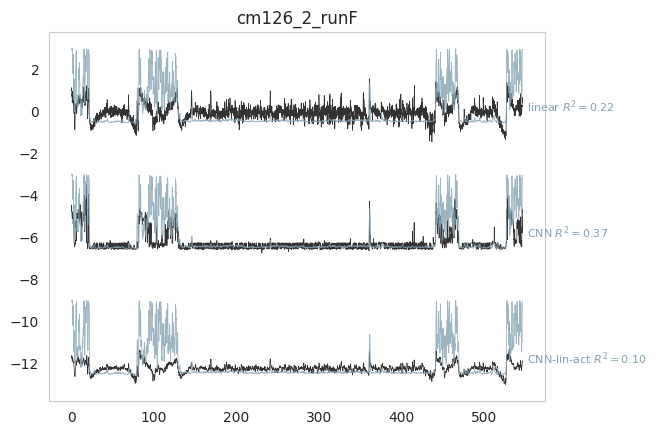

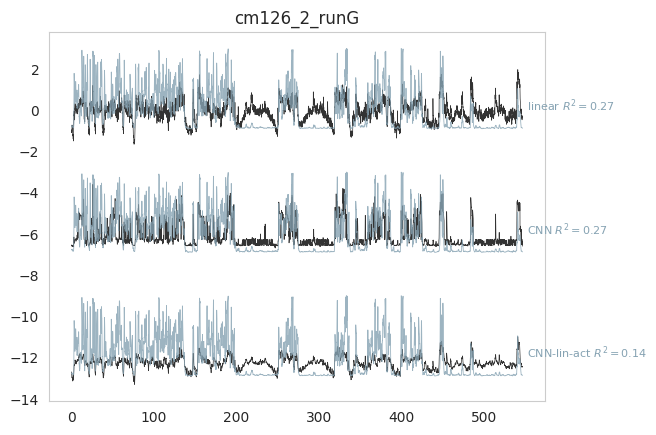

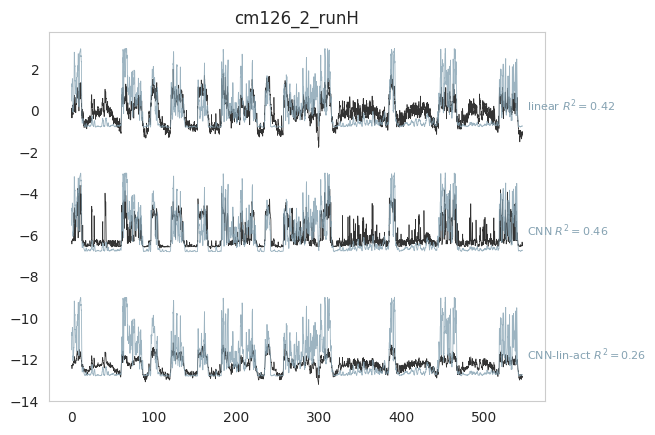

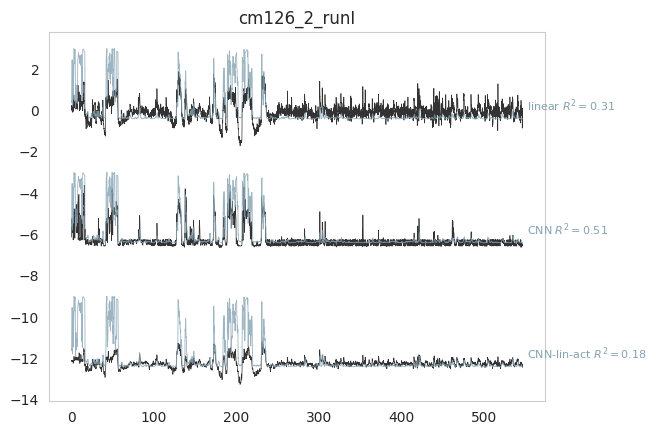

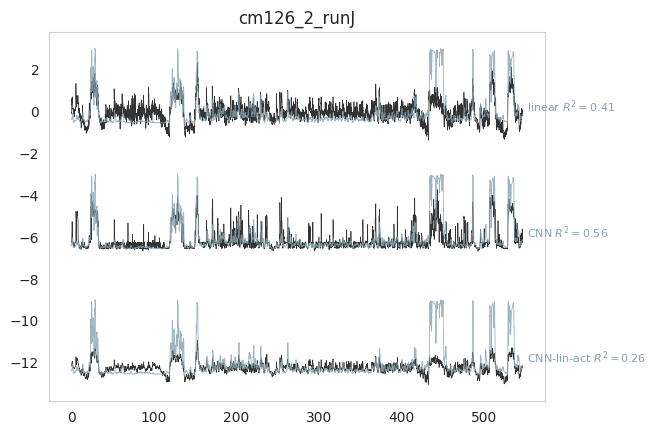

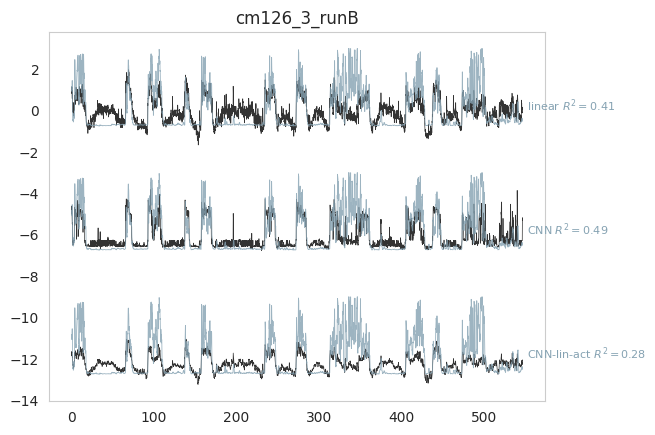

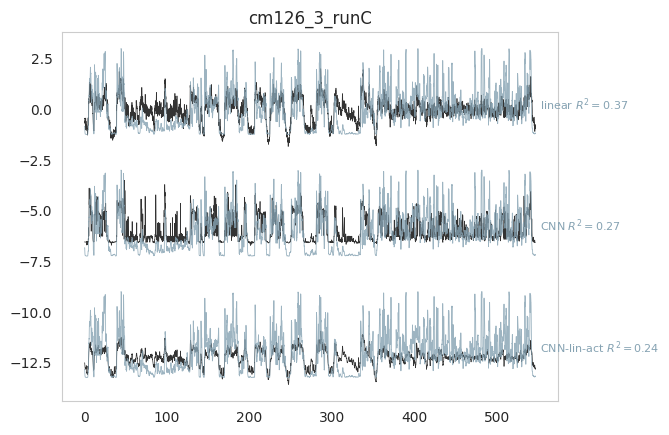

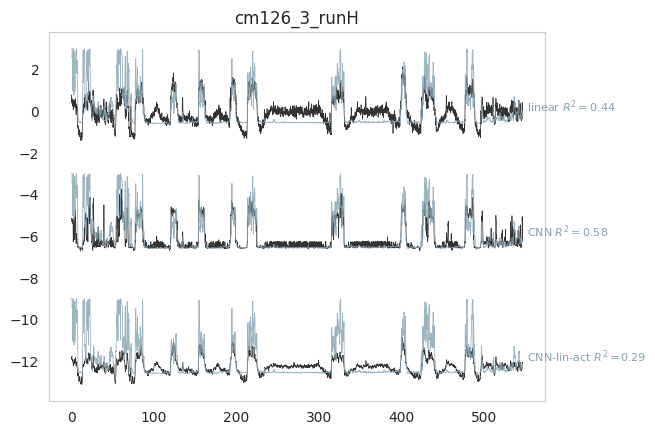

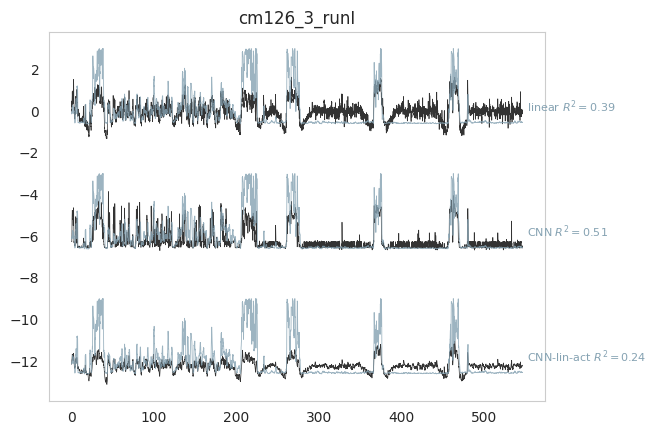

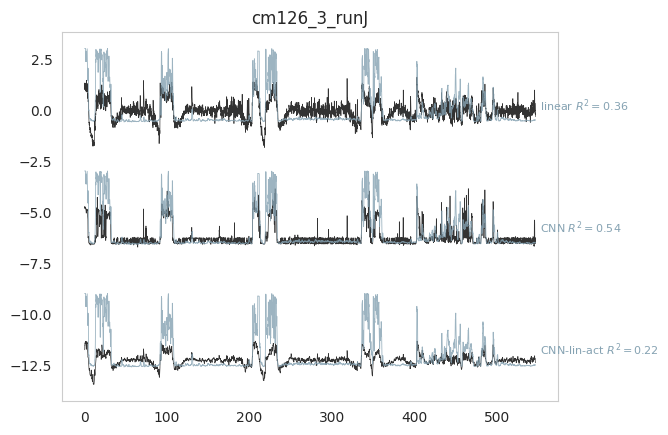

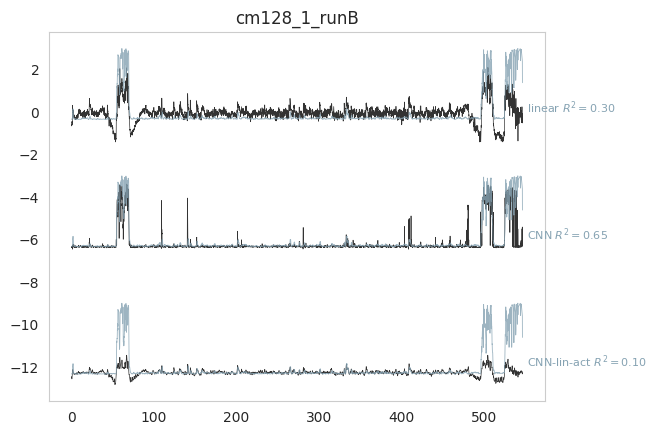

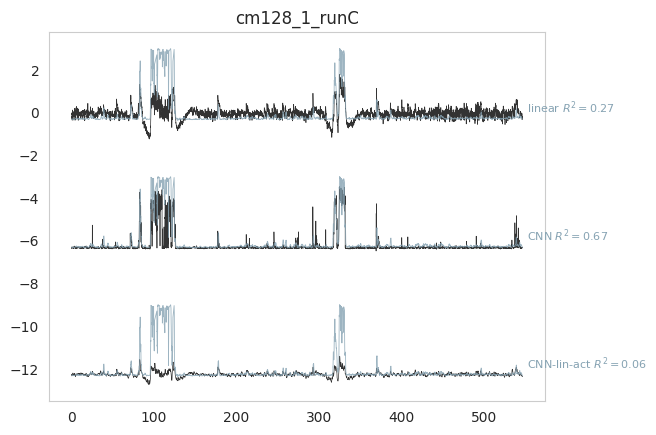

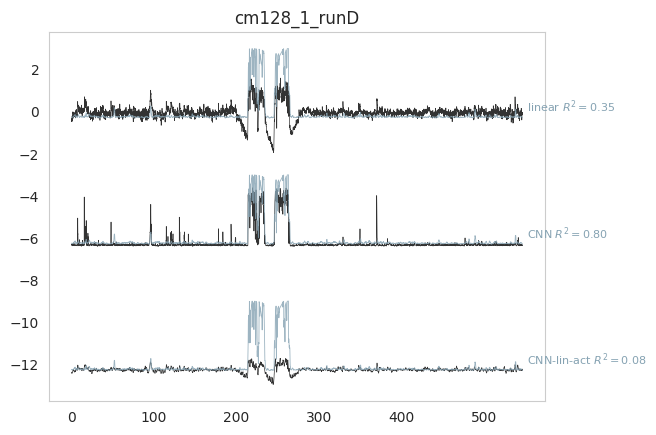

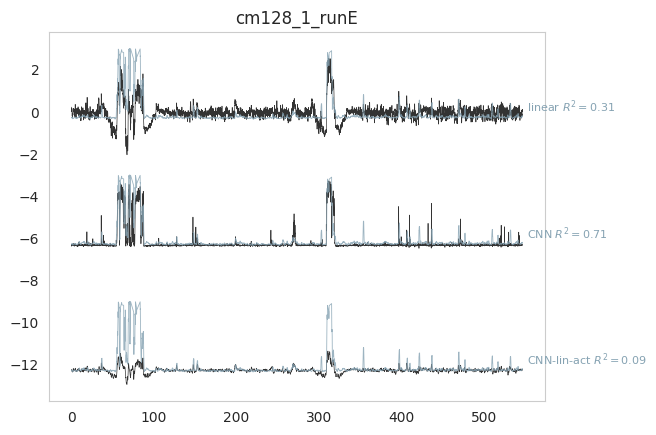

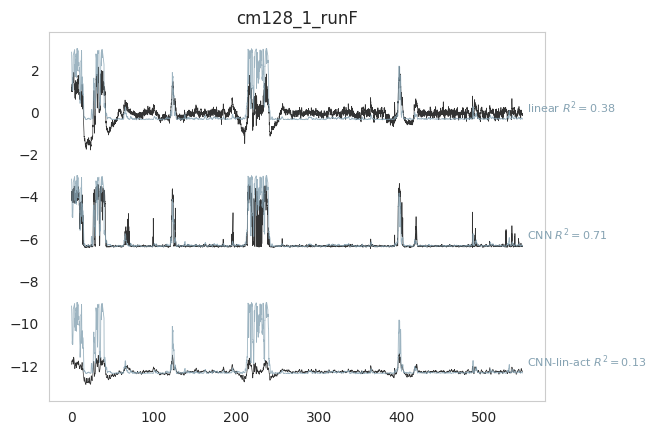

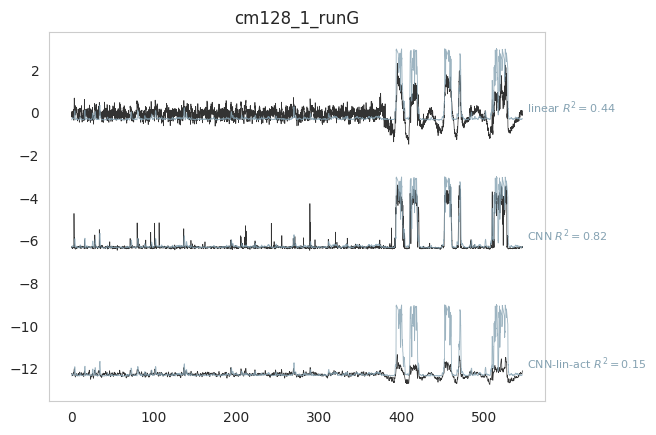

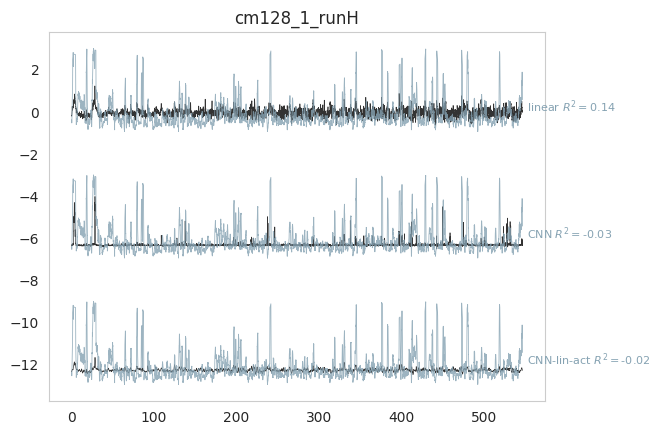

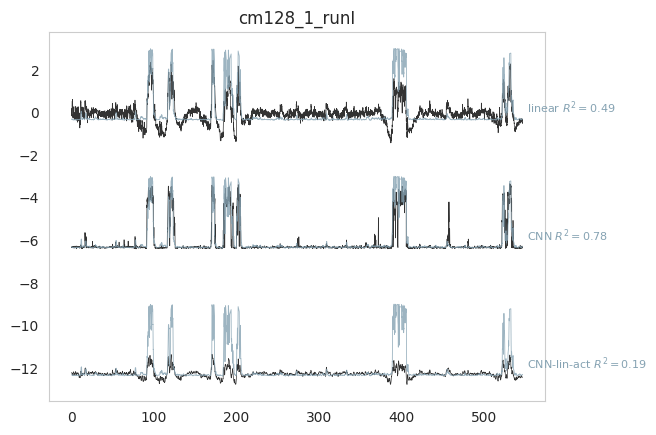

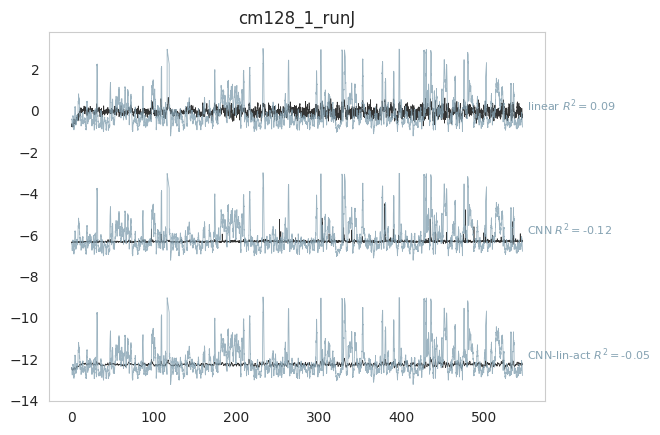

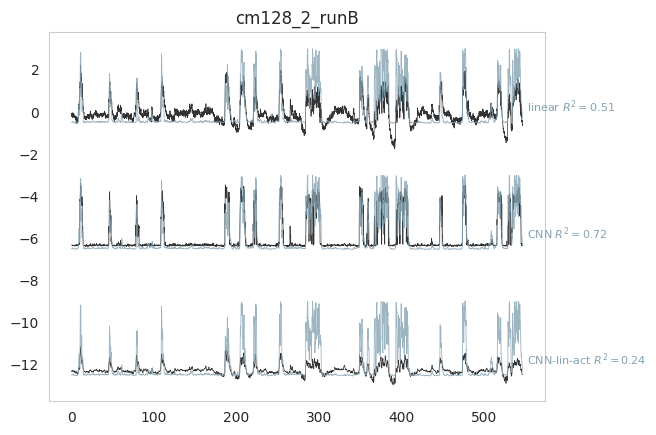

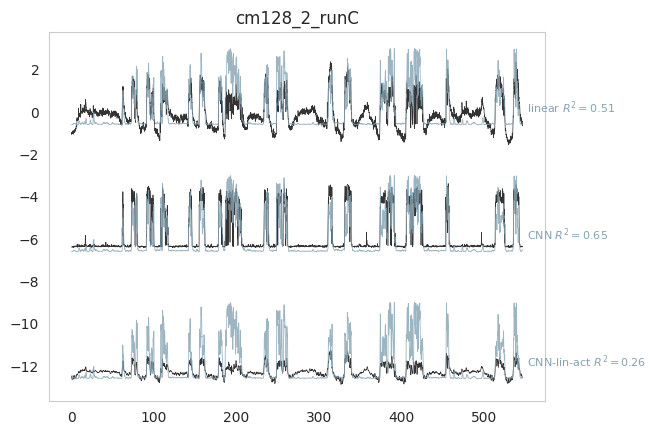

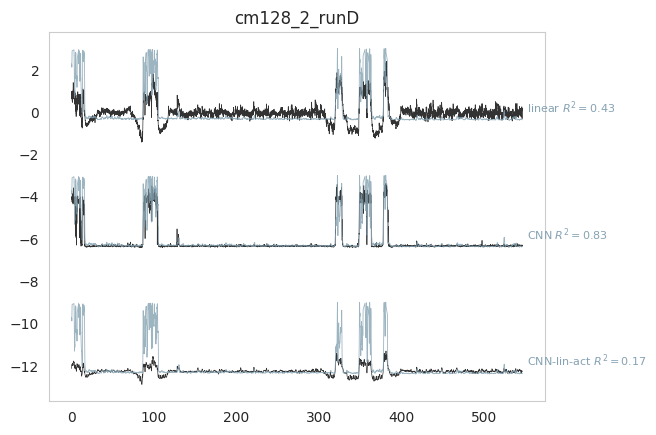

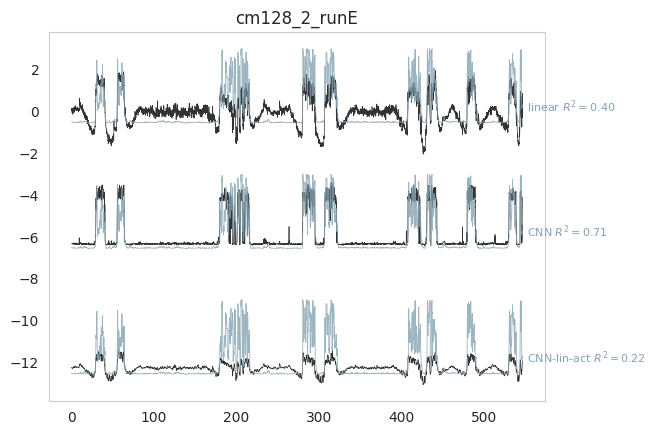

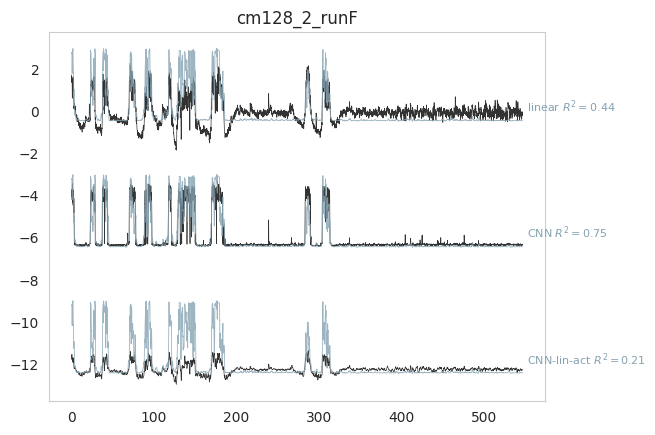

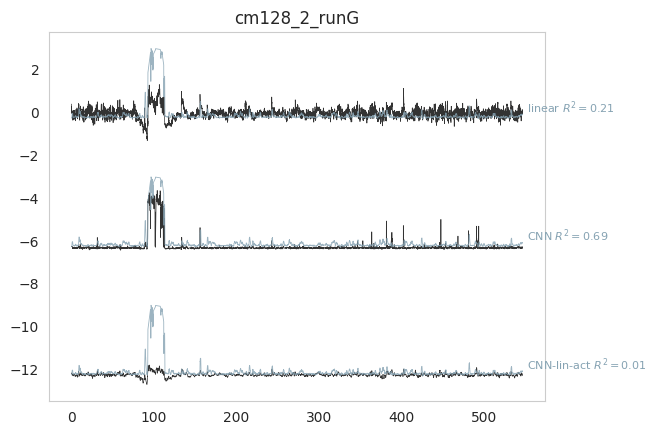

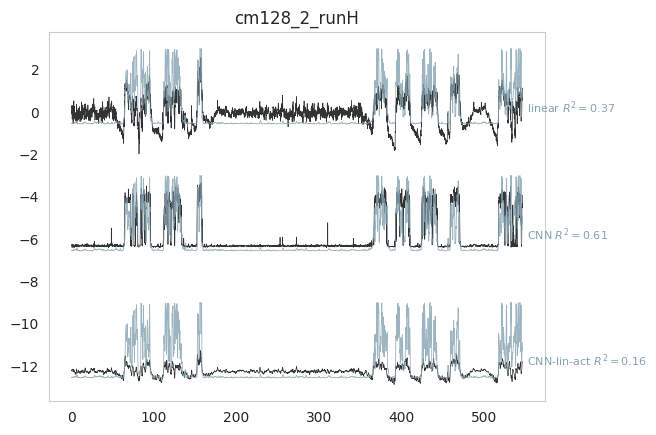

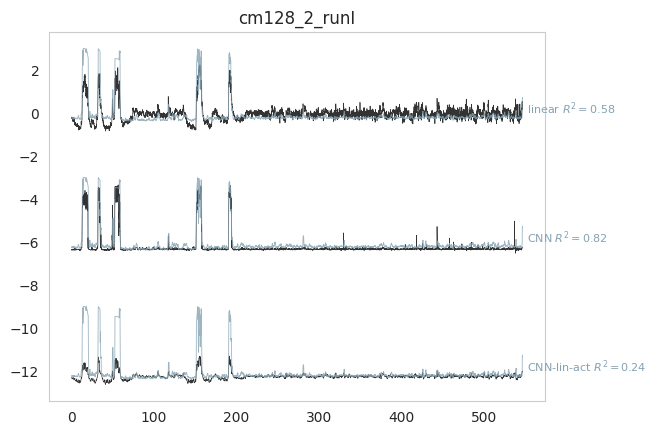

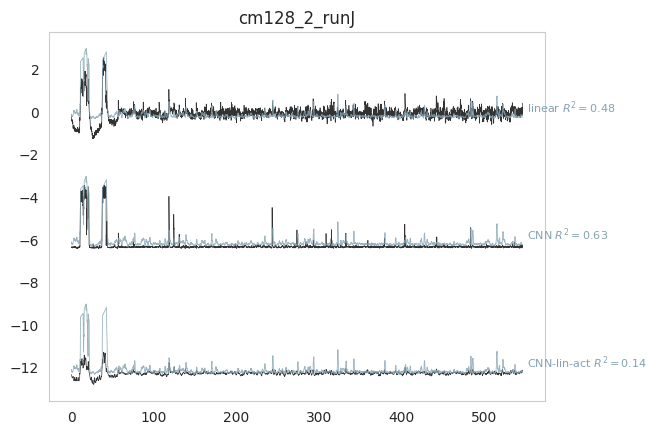

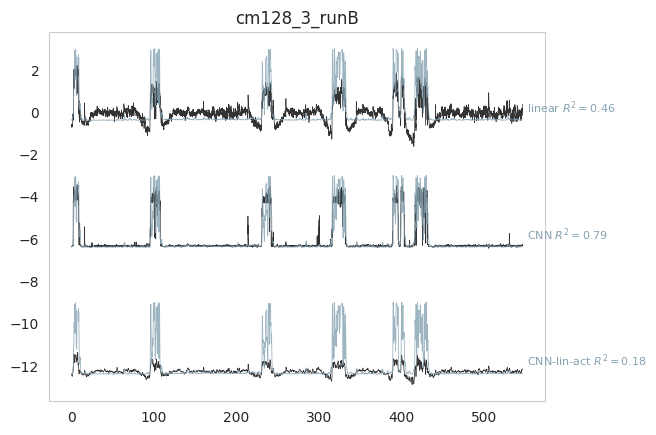

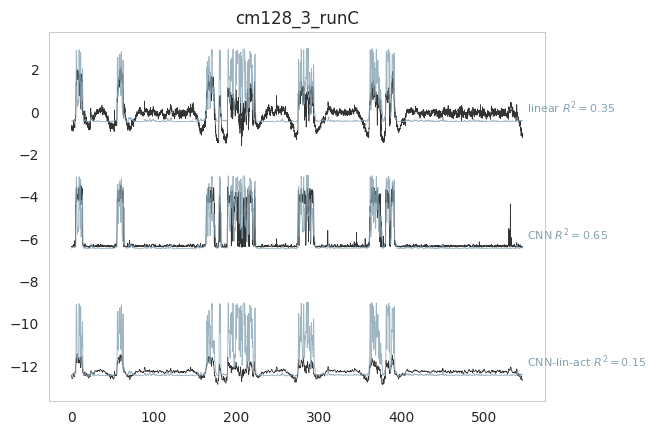

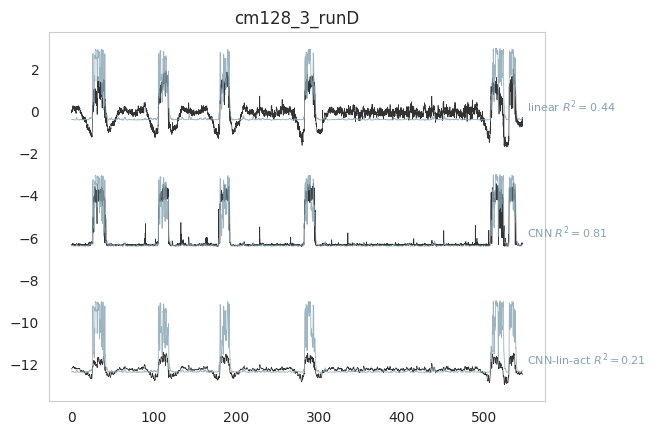

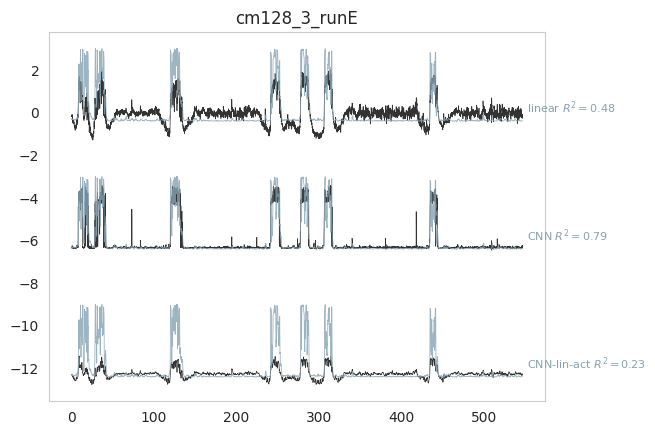

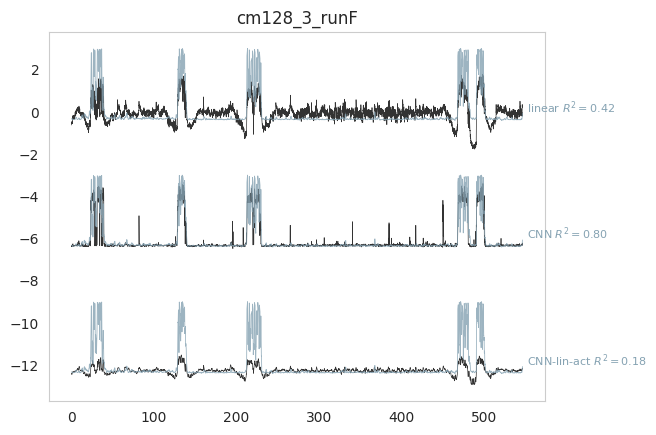

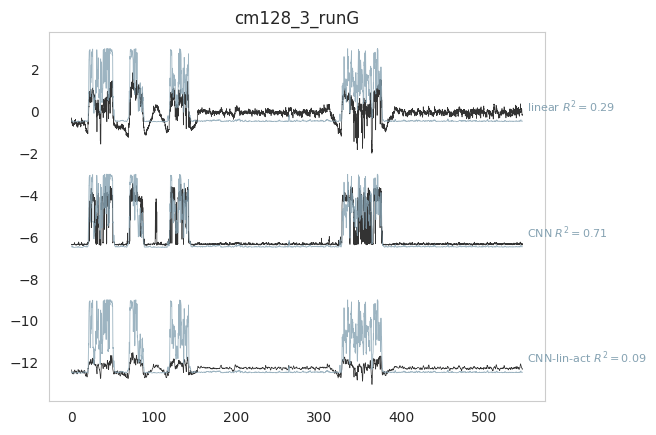

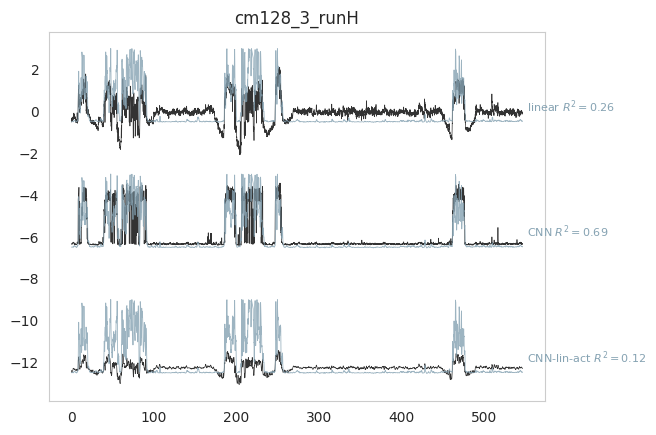

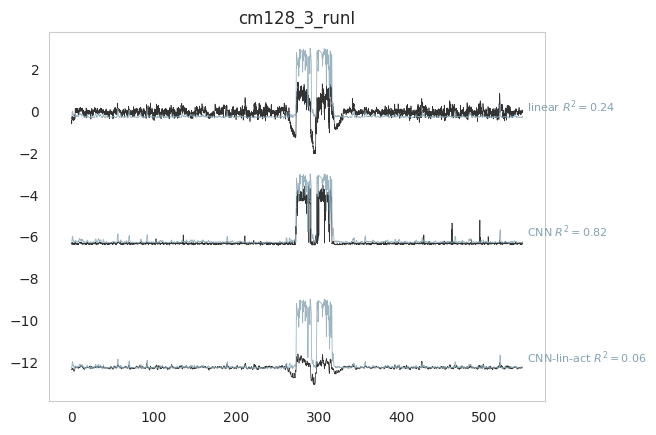

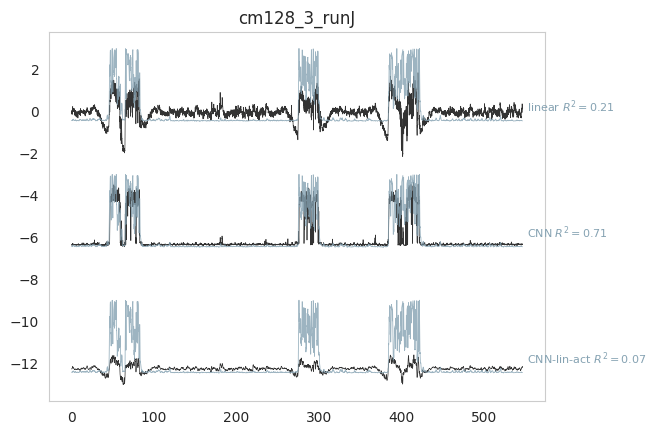

In [43]:
i_beh =1 # only focus on the wheel speed
df_stats = pd.DataFrame()
df_data = pd.DataFrame()

# for mouse in ['cm125','cm128',]:
for mouse in ['cm125','cm126','cm128']:
    print(mouse)
    # load data
    fetch_path = str(PREPARES / "modeling") + "/"
    data_joint = load_pickle(fetch_path+mouse+'_data_joint.pickle')
    all_sessions = list(np.unique(data_joint.index.get_level_values(0)))
    print(len(all_sessions),all_sessions)


    # load linear model
    linear_model = load_pickle(fetch_path+'linear_model_'+mouse)
    
    # load CNN model without LSTM (non-linear)
    length=40
    model_weights_filename = fetch_path+'CNN-without-LSTM/'+'cnn_weights_'+mouse+ '_len_'+str(length)+'.hdf5'

    timesteps=length;num_in_features=500;num_out_features = 4
    cnn_model = prepare_model_without_lstm('mean_absolute_error','mean_absolute_error',
                                            timesteps,
                                           num_in_features,
                                           num_out_features)
    cnn_model.summary()
    cnn_model = load_model(cnn_model, model_weights_filename)

    # CNN model with linear activation
    model_weights_filename = fetch_path+'cnn_weights_linear_act_'+mouse+ '_len_'+str(length)+'.hdf5'
    timesteps=length;num_in_features=500;num_out_features = 4
    cnn_model_linear_act = prepare_model_linear_act('mean_absolute_error','mean_absolute_error',
                                            timesteps,
                                           num_in_features,
                                           num_out_features)
    cnn_model_linear_act.summary()
    cnn_model_linear_act = load_model(cnn_model_linear_act, model_weights_filename)



    
    for session in all_sessions:
        if session == 'cm125_1_runB':
            print('skip ',session)
            continue
        X = np.array(data_joint.loc[session,:].iloc[:,:500])
        y = np.array(data_joint.loc[session,:].iloc[:,500:])

        y_predict_linear_model = linear_model.predict(X)

        from TimeseriesGenerator import TimeseriesGenerator

        data_gen = TimeseriesGenerator(X,y,
                                       stride = 40,sampling_rate=1,
                                       length=40,batch_size=1000000)
        X_CNN , y_CNN = data_gen[0]

        Y_hat = cnn_model.predict(X_CNN)
        Y_hat_concat = Y_hat.reshape((Y_hat.shape[0]*Y_hat.shape[1],Y_hat.shape[-1]))

        Y_hat_linear_act = cnn_model_linear_act.predict(X_CNN)
        Y_hat_concat_linear_act = Y_hat_linear_act.reshape((
            Y_hat_linear_act.shape[0]*Y_hat_linear_act.shape[1],Y_hat_linear_act.shape[-1]))

        df_temp = pd.DataFrame()
        df_data_temp = pd.DataFrame()
        plt.figure()
        t_total = y_predict_linear_model.shape[0]-40
        t_ax = np.divide(range(t_total),20)
        plt.plot(t_ax,y_predict_linear_model[:t_total,i_beh],label='prediction',linewidth=0.5,color='black',alpha=0.8)
        plt.plot(t_ax,y[:t_total,i_beh],label='real test data',color=palette_body[i_beh],linewidth=0.6,alpha=0.8)
        r2 = r2_score(y[:t_total,i_beh],y_predict_linear_model[:t_total,i_beh])
        plt.text(t_ax[-1]-t_ax[0]+5,0,'{} $R^2=${:0.2f}'.format('linear',r2),color=palette_body[i_beh],fontsize=8)
        df_temp.loc[0,'R2']=r2;df_temp.loc[0,'model_type']='linear';

        plt.plot(t_ax,Y_hat_concat[:t_total,i_beh]-6,label='prediction',linewidth=0.5,color='black',alpha=0.8)
        plt.plot(t_ax,y[:t_total,i_beh]-6,label='real test data',color=palette_body[i_beh],linewidth=0.6,alpha=0.8)
        r2 = r2_score(y[:t_total,i_beh],Y_hat_concat[:t_total,i_beh])
        plt.text(t_ax[-1]-t_ax[0]+5,-6,'{} $R^2=${:0.2f}'.format('CNN',r2),color=palette_body[i_beh],fontsize=8)
        df_temp.loc[1,'R2']=r2;df_temp.loc[1,'model_type']='CNN';

        plt.plot(t_ax,Y_hat_concat_linear_act[:t_total,i_beh]-12,label='prediction',linewidth=0.5,color='black',alpha=0.8)
        plt.plot(t_ax,y[:t_total,i_beh]-12,label='real test data',color=palette_body[i_beh],linewidth=0.6,alpha=0.8)
        r2 = r2_score(y[:t_total,i_beh],Y_hat_concat_linear_act[:t_total,i_beh])
        plt.text(t_ax[-1]-t_ax[0]+5,-12,'{} $R^2=${:0.2f}'.format('CNN-lin-act',r2),color=palette_body[i_beh],fontsize=8)
        df_temp.loc[2,'R2']=r2;df_temp.loc[2,'model_type']='CNN-linear-act';

        df_temp['session']=session;df_temp['mouse']=mouse;df_stats = pd.concat([df_stats, df_temp])
        
        # when saving data - remove grooming
        ind_keep_not_groom = np.where(y[:t_total,2] < 0.1)[0]
        df_data_temp['real_test'] = y[ind_keep_not_groom,i_beh];
        df_data_temp['cnn'] = Y_hat_concat[ind_keep_not_groom,i_beh];
        df_data_temp['cnn_linear_act'] = Y_hat_concat_linear_act[ind_keep_not_groom,i_beh];
        df_data_temp['linear'] = y_predict_linear_model[ind_keep_not_groom,i_beh];
        df_data_temp['mouse'] = mouse
        tmp = pd.concat([df_data_temp], keys=[session], names=['row_level'])
        df_data = pd.concat([df_data, tmp])
        
        
        plt.title(session)



In [44]:
dict_df = {'df_data':df_data,
           'df_stats':df_stats}

In [63]:
df_data

real_test       cnn  cnn_linear_act    linear  mouse
row_level                                                               
cm125_1_runC 0      -0.341787 -0.413324       -0.318758  0.036584  cm125
             1      -0.336344 -0.414043       -0.330630  0.005265  cm125
             2      -0.339972 -0.417579       -0.341341  0.041745  cm125
             3      -0.335529 -0.420893       -0.335608  0.067778  cm125
             4      -0.331835 -0.416790       -0.325746  0.126629  cm125
...                       ...       ...             ...       ...    ...
cm128_3_runJ 10909  -0.447600 -0.342121       -0.199681  0.152084  cm128
             10910  -0.450005 -0.349064       -0.202203  0.151014  cm128
             10911  -0.450005 -0.348931       -0.197573  0.203394  cm128
             10912  -0.450005 -0.341356       -0.178994  0.254742  cm128
             10913  -0.451876 -0.341290       -0.151477  0.320616  cm128

[721899 rows x 5 columns]

In [45]:
# save_path = str(PREPARES / "modeling/stats") + "/"
# save_pickle(dict_df,save_path+'dict_df')

In [34]:
# load
save_path = str(PREPARES / "modeling/stats") + "/"
dict_df = load_pickle(save_path+'dict_df')
df_stats = dict_df['df_stats']
df_data = dict_df['df_data']

In [46]:
df_stats = df_stats.reset_index()

In [134]:
for mouse in ['cm125','cm126','cm128']:
    print(mouse,len(df_stats[(df_stats['mouse']==mouse)& (df_stats['model_type']=='linear')]))

cm125 25
cm126 16
cm128 27


In [47]:
box_pairs=[
    (("cm125", "CNN"), ("cm125", "CNN-linear-act")),
    (("cm125", "CNN"), ("cm125", "linear")),
    (("cm126", "CNN"), ("cm126", "CNN-linear-act")),
    (("cm126", "CNN"), ("cm126", "linear")),
    (("cm128", "CNN"), ("cm128", "CNN-linear-act")),
    (("cm128", "CNN"), ("cm128", "linear")),
    ]

In [48]:
import matplotlib
rgb_colors = sns.color_palette('Pastel1', 5)
hex_colors = list(map(matplotlib.colors.rgb2hex, rgb_colors))

In [50]:
new_palette = ['#fbb4ae', '#b3cde3', '#decbe4']

In [51]:
sns.color_palette("Pastel1")

[(0.984313725490196, 0.7058823529411765, 0.6823529411764706),
 (0.7019607843137254, 0.803921568627451, 0.8901960784313725),
 (0.8, 0.9215686274509803, 0.7725490196078432),
 (0.8705882352941177, 0.796078431372549, 0.8941176470588236),
 (0.996078431372549, 0.8509803921568627, 0.6509803921568628),
 (1.0, 1.0, 0.8),
 (0.8980392156862745, 0.8470588235294118, 0.7411764705882353),
 (0.9921568627450981, 0.8549019607843137, 0.9254901960784314),
 (0.9490196078431372, 0.9490196078431372, 0.9490196078431372)]

/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:39: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.



p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

cm126_CNN vs. cm126_CNN-linear-act: Wilcoxon test (paired samples) with Benjamini-Hochberg correction, P_val:3.052e-05 Stat=0.000e+00
cm128_CNN vs. cm128_CNN-linear-act: Wilcoxon test (paired samples) with Benjamini-Hochberg correction, P_val:7.871e-06 Stat=3.000e+00
cm128_linear vs. cm128_CNN: Wilcoxon test (paired samples) with Benjamini-Hochberg correction, P_val:1.371e-05 Stat=8.000e+00
cm125_CNN vs. cm125_CNN-linear-act: Wilcoxon test (paired samples) with Benjamini-Hochberg correction, P_val:5.960e-08 Stat=0.000e+00
cm125_linear vs. cm125_CNN: Wilcoxon test (paired samples) with Benjamini-Hochberg correction, P_val:5.960e-08 Stat=0.000e+00
cm126_linear vs. cm126_CNN: Wilcoxon test (paired samples) with Benjamini-Hochberg correction, P_val:3.052e-04 Stat=5.000e+00


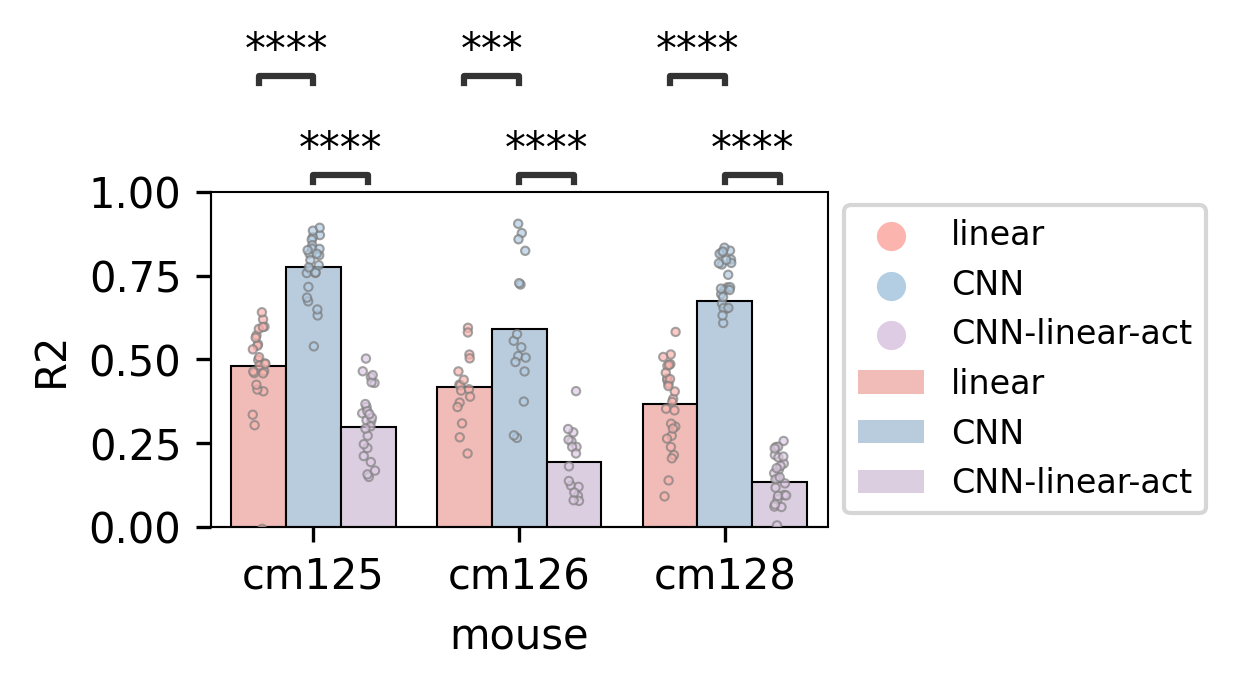

In [127]:
from matplotlib.gridspec import GridSpec
from matplotlib import colors
from skimage import measure
import matplotlib
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
from statannotations.Annotator import Annotator

fmt = lambda x, pos: '{:.0%}'.format(x)
plt.style.use('default')
gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;x_width=5

# temporal std average brain map (rest and run)
x_start = x_offset 
x_stop = x_offset+9
ax0 = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])


# my_pal = {key:palatte_dict[key] for i,key in enumerate(all_body_part) }


# ax_violin = sns.violinplot(x="mouse", y="std_diff", hue="region", palette=my_pal,
#        data=diff_pot,density_norm="width", linewidth=0.5,inner=None,ax=ax0)
# xlim = ax_violin.get_xlim()
# ylim = ax_violin.get_ylim()
# for violin in ax_violin.collections:
#     bbox = violin.get_paths()[0].get_extents()
#     x0, y0, width, height = bbox.bounds
#     violin.set_clip_path(plt.Rectangle((x0-0.05, y0), width / 2, height, transform=ax_violin.transData))

        
        
sbp = sns.barplot(x="mouse", y="R2", hue="model_type", palette=new_palette,
       data=df_stats,ci=None,linewidth=1,ax=ax0)
            # saturation=1, showfliers=False,boxprops={'zorder': 5, 'facecolor': 'none'},
            # linewidth=1, ax=ax0)


# new_adjust_box_widths(ax0, fac=0.5)

# sns.stripplot(x="mouse", y="std_diff", hue="region",palette=my_pal,
#        data=diff_pot,dodge=True,
#     color='dodgerblue',size=1, ax=ax0)
    

# # sns.boxplot(x="mouse", y="std_diff", hue="region", palette=my_pal,linewidth=1,data=diff_pot_all,showfliers=False,boxprops=dict(alpha=.7))
sns.stripplot(x="mouse", y="R2", hue="model_type", data=df_stats,
              jitter=True,
              palette=new_palette,
              linewidth=0.5,
              size=2,
              alpha=0.7,
              edgecolor='gray',
              dodge=True,
              ax=ax0
             )
ax0.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=8)

import matplotlib.patches

# grab everything that is on the axis
children = sbp.get_children()

# filter for rectangles
for child in children:
    if isinstance(child, matplotlib.patches.Rectangle):
        # match edgecolors to facecolors
        # clr = child.get_facecolor()
        child.set_edgecolor('black')
        child.set_linewidth(0.5)
        

ax0.set_ylim([0,1])
# ax0.axhline(0,color='#3778bf',linewidth=1,linestyle='dashed',zorder=0)

    

annotator = Annotator(ax0, box_pairs,data=df_stats, x='mouse', y='R2',hue="model_type")#, order=bodyparts_list)
annotator.configure(test='Wilcoxon', text_format='star', comparisons_correction="BH", 
                    loc='outside',)
annotator.apply_and_annotate()

for axis in ['left','bottom','top','right']:
    ax0.spines[axis].set_linewidth(0)
for axis in ['left','bottom']:
    ax0.spines[axis].set_linewidth(0.5)
    
plt.savefig('figS7-model-compare-STATS.svg',format='svg',dpi=300)

# Confusion matrix

In [103]:
from sklearn.metrics import confusion_matrix
detect_threshold = -0.1
cm_all_cnn = np.empty((2,2,0))
for mouse in ['cm125','cm126','cm128']:
    df_data_per_mouse = df_data[df_data['mouse']==mouse]
    cm = confusion_matrix(df_data_per_mouse['real_test']>detect_threshold,
                          df_data_per_mouse['cnn']>detect_threshold)
    cm_all_cnn = np.append(cm_all_cnn,cm[:,:,np.newaxis],axis=-1)
    
cm_all_linear = np.empty((2,2,0))
for mouse in ['cm125','cm126','cm128']:
    df_data_per_mouse = df_data[df_data['mouse']==mouse]
    cm = confusion_matrix(df_data_per_mouse['real_test']>detect_threshold,
                          df_data_per_mouse['linear']>detect_threshold)
    cm_all_linear = np.append(cm_all_linear,cm[:,:,np.newaxis],axis=-1)

In [102]:
# plt.plot(df_data_per_mouse['real_test'].values[:10000])
# plt.plot(df_data_per_mouse['cnn'].values[:10000])
# plt.plot(df_data_per_mouse['linear'].values[:10000])
# plt.axhline(-0.2)

In [125]:
import itertools
#Evaluation of Model - Confusion Matrix Plot For Many Mice
def plot_confusion_matrix_for_many_mice(ax,cm_all, classes,colors,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    cm = np.mean(cm_all,axis=-1)
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        cm_all = cm_all.astype('float') / cm_all.sum(axis=1)[:, np.newaxis,:]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    sbp = ax.imshow(cm, interpolation='nearest', cmap=cmap,vmin=0,vmax=1)
    ax.set_title(title)
    tick_marks = np.arange(len(classes))
    ax.set_xticks(tick_marks, classes, rotation=0)
    ax.set_yticks(tick_marks, classes)
    

    from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
    div = make_axes_locatable(ax)
    cax = div.append_axes('right', '6%', '6%')
    cb = fig.colorbar(sbp, cax=cax,orientation='vertical')#,format=FuncFormatter(fmt))
    cb.ax.tick_params(labelsize=9,length=3,color='black')
    cb.ax.yaxis.tick_right()
    cb.outline.set_edgecolor('black')
    cb.outline.set_linewidth(0.7)
    
    
    fmt = '.2f' if normalize else 'd'

    for i_cm in range(cm_all.shape[-1]):
        for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
            ax.text(j, i+0.22*i_cm-0.1, format(cm_all[i, j, i_cm], fmt),
                     horizontalalignment="center",color=colors[i_cm])
        
    ax.set_ylabel('True label')
    ax.set_xlabel('Predicted label')
    # plt.tight_layout()


Normalized confusion matrix
[[0.54174974 0.45825026]
 [0.11174059 0.88825941]]
Normalized confusion matrix
[[0.9826803  0.0173197 ]
 [0.22671478 0.77328522]]


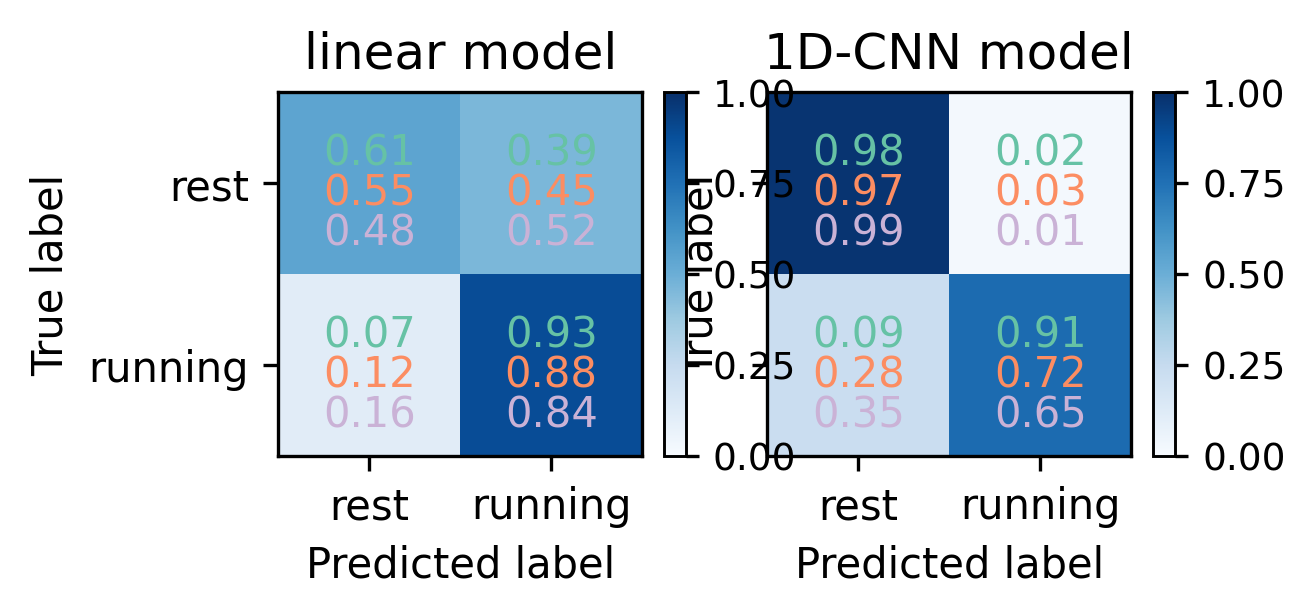

In [128]:
from matplotlib.gridspec import GridSpec
from matplotlib import colors
from skimage import measure
import matplotlib
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
from statannotations.Annotator import Annotator

fmt = lambda x, pos: '{:.0%}'.format(x)
plt.style.use('default')
gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;x_width=5

# temporal std average brain map (rest and run)
x_start = x_offset 
x_stop = x_offset+6
ax0 = fig.add_subplot(gs[y_offset:y_offset+6,x_start:x_stop])
x_start = x_stop +1 
x_stop = x_start+6
ax1 = fig.add_subplot(gs[y_offset:y_offset+6,x_start:x_stop])

plot_confusion_matrix_for_many_mice(ax0,cm_all_linear, classes=['rest','running'],colors=col,
                                   normalize=True,
                      title='linear model')
plot_confusion_matrix_for_many_mice(ax1,cm_all_cnn, classes=['rest','running'],colors=col,
                                  normalize=True,
                      title='1D-CNN model')
ax1.set_yticklabels([])
plt.savefig('figS7-model-compare-confusion-matrix.svg',format='svg',dpi=300)